# 20 · Classification views of the task (E48)

1. **Viral**: is a post in the top 10% of views of its platform? Scores: followers, the Brand24 reach column (X only: on TikTok and YouTube it equals the views), the final regression model and a CatBoost classifier, on held-out brands.
2. **No views**: which TikTok / YouTube / X posts have a view count of 0 or none at all, can that be predicted, and what does the final model say about the zero-view posts it never trains on?

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "figures"; plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 220, "display.max_columns", 30)
import extra_models as em, classification as cl

In [2]:
f, meta = em.load(ROOT)
V = cl.viral(f, meta); T = cl.viral_table(V)
T.round(3)

,platform,score,posts,viral,ROC AUC,AUC low,AUC high,avg precision,AP low,AP high,precision top 10%,P@10 low,P@10 high
0,tiktok,followers,2491,252,0.753,0.722,0.785,0.319,0.261,0.384,0.357,0.294,0.416
1,tiktok,regression (final model),2491,252,0.983,0.976,0.988,0.904,0.871,0.929,0.827,0.725,0.890
2,tiktok,classifier (CatBoost),2491,252,0.977,0.968,0.984,0.887,0.850,0.915,0.799,0.709,0.881
3,youtube,followers,2441,247,0.836,0.800,0.863,0.427,0.338,0.508,0.439,0.361,0.512
4,youtube,regression (final model),2441,247,0.935,0.908,0.954,0.794,0.737,0.840,0.713,0.610,0.803
5,youtube,classifier (CatBoost),2441,247,0.925,0.899,0.944,0.786,0.728,0.830,0.713,0.613,0.790
6,twitter,followers,1803,183,0.774,0.736,0.812,0.298,0.245,0.380,0.428,0.339,0.514
7,twitter,Brand24 reach,1803,183,0.899,0.864,0.924,0.656,0.580,0.731,0.622,0.528,0.715
8,twitter,regression (final model),1803,183,0.894,0.859,0.921,0.680,0.619,0.744,0.633,0.540,0.714
9,twitter,classifier (CatBoost),1803,183,0.896,0.861,0.925,0.656,0.588,0.724,0.628,0.544,0.703


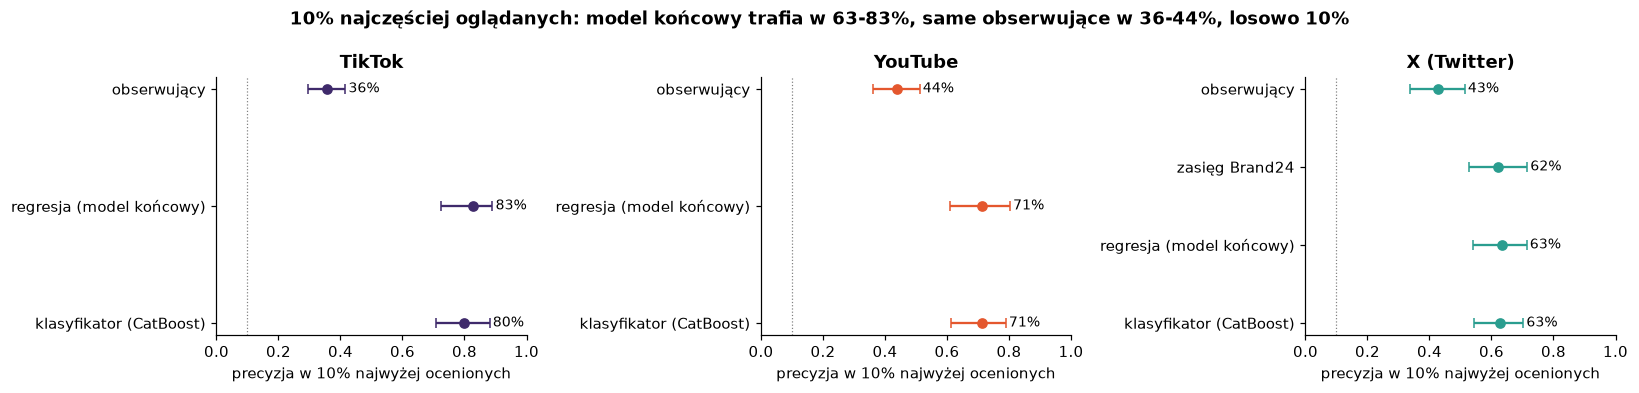

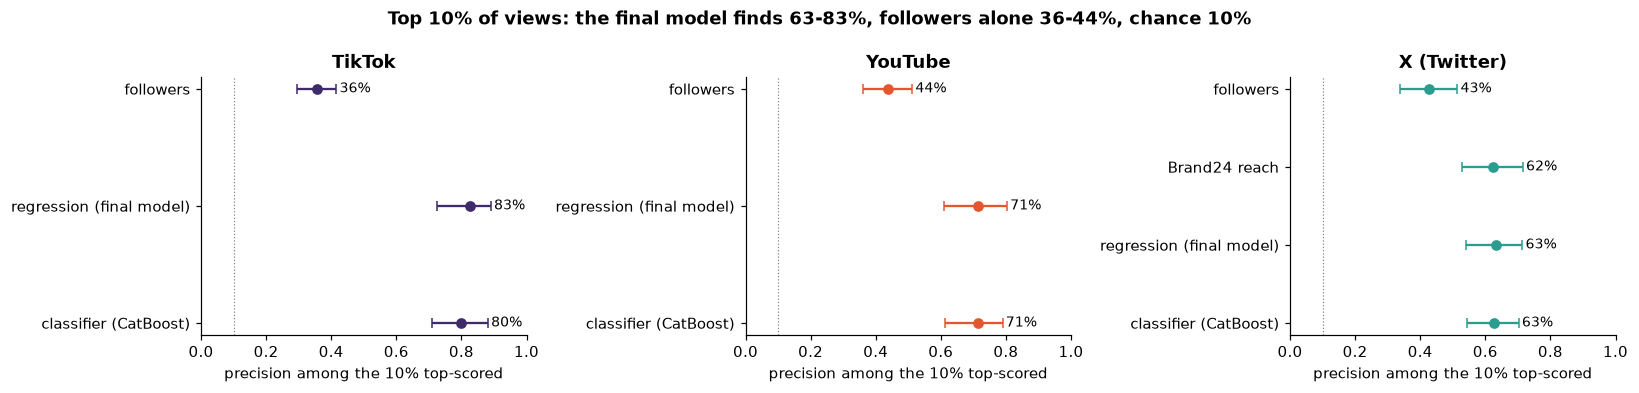

In [3]:
for l in ("pl", "en"): cl.plot_viral(T, FIG / f"viral_top10_{l}.png", l)

## No view count
Median of each feature by status. `post_year` is the posting date in years.

In [4]:
N = cl.no_views(ROOT); Pf = cl.no_views_profile(N); Pf.round(2)

posts  post_year  age_days  log_followers  log_likes  log_comments  na_likes  na_comments  text_len
platform views                                                                                                       
tiktok   present   2491    2026.42     35.76           3.19       3.50          1.10       0.0          0.0      2.21
         zero         9    2026.33     33.79           1.97       0.00          0.00       0.0          0.0      2.87
twitter  missing    634    2026.25     65.93           2.46       0.00          0.69       0.0          1.0      2.28
         present   1803    2026.42     21.03           2.72       0.00          0.69       0.0          1.0      2.36
         zero        63    2025.08    139.46           2.07       0.00          0.00       0.0          0.0      2.33
youtube  missing     27    2026.58      1.29           1.88       0.00          0.00       1.0          1.0      2.75
         present   2441    2026.42     25.21           4.46       2.08          0.69       0.0          0.0      2.89
         zero        32    2026.50      5.22           4.09       0.00          0.00       0.0          0.0      2.21

In [5]:
A = cl.no_views_auc(N); A.round(3)

,platform,posts,no views,ROC AUC,AUC low,AUC high,top features
0,tiktok,2500,9,NaN,NaN,NaN,NaN
1,youtube,2500,59,0.949,0.933,0.969,"log_likes 31, age_days 19, log_followers 15"
2,twitter,2500,697,0.910,0.887,0.930,"age_days 33, log_likes 17, post_year 15"


In [6]:
Y = N.assign(year=N.created_at.dt.year).groupby(["platform", "year", "views"]).size().unstack(fill_value=0); Y

views          missing  present  zero
platform year                        
tiktok   2025        0      180     2
         2026        0     2311     7
twitter  2025      113       12    45
         2026      521     1791    18
youtube  2025        9      167     4
         2026       18     2274    28

## What the final model predicts for posts with 0 views

In [7]:
Z = cl.zero_view_predictions(f, meta, N); Z.round(3)

,platform,zero-view posts,median predicted views,share predicted < 10 views,share with 0 likes and comments
0,tiktok,9,87.208,0.000,1.000
1,youtube,32,9.068,0.562,1.000
2,twitter,63,14.829,0.333,0.619


## Takeaways
See `docs/en/experiments.md` (E48) and `agent/vault/E48.md`. Numbers: `data/processed/classification_numbers.json`.

In [8]:
json.dump({"viral": T.to_dict("records"), "no_views_profile": Pf.reset_index().to_dict("records"), "no_views_auc": A.to_dict("records"), "by_year": Y.reset_index().to_dict("records"), "zero_view_predictions": Z.to_dict("records")},
          open(ROOT / "data" / "processed" / "classification_numbers.json", "w"), indent=1, default=float)